# Classification

This notebook implements the slice-level nodule-presence classification stage. Before running this notebook, the initial setup cells from the Main Ablation Study notebook must be executed to define the model architecture, dataset classes, configurations, and required functions.

Unlike the segmentation stage, which excluded certain positive samples, including nodules with a malignancy score of 3 and nodules with a polygon area smaller than 100 pixels, the classification stage uses all positive samples, including these previously excluded cases. In total, 38,229 positive slices are included in the classification dataset.

The selected 2.5D decoder-attention segmentation model is loaded first and used as the feature extraction backbone. The extracted deep features and segmentation-derived features are then used to train and evaluate the classification model.

The classification experiments were conducted using both the selected 2.5D_DecAtt model and the 2D_Baseline model. However, the main classification results are reported for the selected 2.5D_DecAtt model, while the baseline results are presented only for comparison.

### Load the Selected Segmentation Model

The selected 2.5D decoder-attention segmentation model (2.5D_DecAtt_S41) was loaded as the feature extraction backbone for the classification stage. This model was selected based on the results of the segmentation ablation study.

The model uses three consecutive axial slices as input, with decoder attention enabled and encoder attention disabled. Full-size 320×320 images are used without cropping to preserve the original spatial and anatomical context.

The encoder features and predicted segmentation outputs are subsequently used to derive deep and segmentation-based features for slice-level nodule-presence classification. The segmentation model remains fixed during this stage.

In [ ]:

# ============================================================
# CELL 1 — Load the Selected Segmentation Model
# Configuration: 2.5D_DecAtt_S41
# ============================================================

import os
import torch
import numpy as np
from tqdm import tqdm
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cfg = dict(
    name="2.5D_DecAtt",
    use_25d=True,
    enc_att=False,
    dec_att=True,
    use_crop=False
)

in_channels = IN_CHANNELS if cfg["use_25d"] else 1

model = SwinUNetAdaptive_DS(
    in_ch=in_channels,
    use_enc_att=cfg["enc_att"],
    use_dec_att=cfg["dec_att"]
).to(device)

best_path = os.path.join(
    "Checkpoints",
    f"best_model_{cfg['name']}.pt"
)

if not os.path.isfile(best_path):
    raise FileNotFoundError(f"Checkpoint not found: {best_path}")

checkpoint = torch.load(best_path, map_location=device)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "model_state" in checkpoint:
    state_dict = checkpoint["model_state"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

model.load_state_dict(state_dict, strict=True)
model.eval()

print(f"Segmentation model: {cfg['name']}")
print(f"Input channels: {in_channels}")
print(f"Device: {device}")
print("Best segmentation model loaded successfully.")


Segmentation model: 2.5D_DecAtt
Input channels: 3
Device: cuda
Best segmentation model loaded successfully.


---------------------------

#### Negative Patient Identification
This cell identifies the patients contributing negative (nodule-free) slices by extracting patient IDs from the image filenames.

In [ ]:
from pathlib import Path
import re

NEG_DIR = Path("Negative_Dataset")

neg_imgs = list(NEG_DIR.glob("*.png"))

def extract_patient_id(name):
    m = re.search(r'(LIDC-IDRI-\d+)', name)
    if m:
        return m.group(1)
    return name.split("_")[0]

neg_patients = set()

for p in neg_imgs:
    pid = extract_patient_id(p.name)
    neg_patients.add(pid)

print("Negative patients:", len(neg_patients))

Negative patients: 219


------------------------

#### Negative Dataset Preparation and Patient-Level Splitting
This cell creates the negative dataset by collecting image paths, patient IDs, and sample labels. All samples are assigned a negative label (0). The dataset is then divided into training, validation, and test sets using patient-level splitting to prevent patient overlap between subsets.

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
import re
from sklearn.model_selection import GroupShuffleSplit

SEED = 42

NEG_DIR = Path(r"Negative_Dataset")
neg_imgs = list(NEG_DIR.glob("*.png"))

def parse_id_idx(name):
    m = re.search(r'(LIDC-IDRI-\d+)', name)
    pid = m.group(1) if m else name.split("_")[0]

    idx_match = re.search(r'(\d+)\.png$', name)
    idx = int(idx_match.group(1)) if idx_match else 0

    return pid, idx

# ==========================================
# 1. Create df_neg
# ==========================================
rows = []

for p in neg_imgs:
    pid, idx = parse_id_idx(p.name)

    rows.append({
        "image_path": str(p),
        "mask_path": None,
        "image_name": p.name,
        "patient_id": pid,
        "idx": idx,
        "label": 0,
        "malignancy": 0,
        "polygon_area": 0
    })

df_neg = pd.DataFrame(rows)

print("Total negative samples:", len(df_neg))

# ==========================================
# 2. Patient-level split for negative dataset
# ==========================================
indices = np.arange(len(df_neg))
groups = df_neg["patient_id"].values

gss1 = GroupShuffleSplit(test_size=0.3, random_state=SEED)
tr_idx, tv_idx = next(gss1.split(indices, groups=groups))

gss2 = GroupShuffleSplit(test_size=0.5, random_state=SEED)
va_rel, te_rel = next(gss2.split(tv_idx, groups=groups[tv_idx]))

df_neg["split"] = "train"
df_neg.loc[tv_idx[va_rel], "split"] = "val"
df_neg.loc[tv_idx[te_rel], "split"] = "test"

print(df_neg["split"].value_counts())

Total negative samples: 46498
split
train    32449
val       7430
test      6619
Name: count, dtype: int64


In [ ]:
#Save Negative Dataset
df_neg.to_csv("negative_dataset.csv", index=False)
print("✅ Saved: negative_dataset.csv")

✅ Saved: negative_dataset.csv


--------------------------------


### Comprehensive Data Leakage Audit

This cell performs a comprehensive audit of potential data leakage across the segmentation and classification stages. The purpose of this analysis is to verify the integrity of the patient-level data splits and ensure that no patient or image is unintentionally shared between datasets or experimental stages.

The audit uses the saved patient-level splits from the segmentation stage (`segmentation_patient_splits.pkl`) and the aligned classification feature dataset (`Final_Feature_MergedPosNeg_2.5D_DecAtt_S41_ALIGNED_FULL_FIXED.csv`). Both files must be generated before running this cell.

The following checks are performed:

1. **Segmentation Split Integrity:** Verifies that the training, validation, and test sets in the segmentation stage contain mutually exclusive patients.

2. **Positive/Negative Cohort Separation:** Checks for patient overlap between the positive and negative classification cohorts. It also verifies that no negative-cohort patient appears in the segmentation dataset.

3. **Classification Split Integrity:** Independently examines patient-level separation across the training, validation, and test sets for the positive cohort, negative cohort, and combined classification dataset.

4. **Patient-Level Split Consistency:** Ensures that each patient is assigned to only one split within each classification cohort.

5. **Cross-Stage Segmentation-to-Classification Leakage:** Examines all six possible cross-stage overlaps between the segmentation and positive classification splits. This check ensures that patients used in one segmentation split do not appear in a different classification split, thereby preventing potential information leakage across the two stages.

6. **Duplicate Row and Image Checks:** Identifies duplicate records based on patient IDs and image names. If image paths are available, it also checks whether the same image path appears in multiple classification splits.

7. **Dataset Reconciliation:** Verifies that the total number of samples across the training, validation, and test sets matches the total number of records in the aligned classification dataset.

8. **Split Distribution Summary:** Reports the number of positive and negative samples in each classification split, along with the number of unique patients in each cohort and split.

All checks are executed independently, and their results are collected in a consolidated PASS/FAIL table. A failed check does not prevent the remaining checks from running. The final summary reports the number of passed and failed checks and provides details of any detected overlaps or inconsistencies.

The complete results of this audit are presented in **Table 16**, including the individual leakage checks and their corresponding PASS/FAIL statuses. The split distribution tables provide additional information about the composition of the classification dataset.

A PASS result indicates that no issue was detected by the corresponding check. However, these checks specifically address patient-level separation, cohort overlap, duplicate records, and dataset consistency; they do not independently rule out other potential sources of leakage, such as information introduced during preprocessing or feature selection.


In [ ]:

# ============================================================
# COMPREHENSIVE DATA LEAKAGE AUDIT
#
# All checks are executed independently, even if one or more
# checks fail. A complete PASS/FAIL summary is displayed at
# the end of the audit.
#
# Prerequisites:
#   1. segmentation_patient_splits.pkl
#      (generated by Save_Segmentation_Splits_ONCE.py)
#   2. The aligned classification feature CSV.
# ============================================================

import os
import pickle
import numpy as np
import pandas as pd
from IPython.display import display


# ============================================================
# Configuration
# ============================================================

ALIGNED_CSV = r"Classification\Final_Feature_MergedPosNeg_2.5D_DecAtt_S41_ALIGNED_FULL_FIXED.csv"

SPLITS_PKL = r"segmentation_patient_splits.pkl"

results = []


# ============================================================
# Helper Function
# ============================================================

def check(section, name, passed, detail=""):
    """Record and print the result of an individual audit check."""

    status = "PASS" if passed else "FAIL"
    results.append((section, name, status, detail))

    icon = "✓" if passed else "✗"
    detail_text = f" | {detail}" if detail else ""

    print(f"{icon} [{section}] {name}{detail_text}")


def patient_sets_by_split(sub_df):
    """Return patient sets for train, validation, and test splits."""

    train_patients = set(
        sub_df.loc[sub_df["split"] == "train", "patient_id"]
    )

    val_patients = set(
        sub_df.loc[sub_df["split"] == "val", "patient_id"]
    )

    test_patients = set(
        sub_df.loc[sub_df["split"] == "test", "patient_id"]
    )

    return train_patients, val_patients, test_patients


# ============================================================
# SECTION 0: DATA LOADING
# ============================================================

print("\n" + "=" * 75)
print("SECTION 0: DATA LOADING")
print("=" * 75)

if not os.path.exists(SPLITS_PKL):
    raise FileNotFoundError(
        f"Required file '{SPLITS_PKL}' was not found. "
        "Run Save_Segmentation_Splits_ONCE.py first."
    )

if not os.path.exists(ALIGNED_CSV):
    raise FileNotFoundError(
        f"Required classification file '{ALIGNED_CSV}' was not found."
    )

with open(SPLITS_PKL, "rb") as f:
    seg_splits = pickle.load(f)

seg_train_p = set(seg_splits["train"])
seg_val_p = set(seg_splits["val"])
seg_test_p = set(seg_splits["test"])

df = pd.read_csv(ALIGNED_CSV)

required_columns = [
    "patient_id",
    "image_name",
    "label",
    "split"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns in the classification CSV: "
        f"{missing_columns}"
    )

print(f"Total classification rows: {len(df):,}")
print(f"Unique classification patients: {df['patient_id'].nunique():,}")

pos_df = df[df["label"] == 1].copy()
neg_df = df[df["label"] == 0].copy()

print(f"Positive samples: {len(pos_df):,}")
print(f"Negative samples: {len(neg_df):,}")


# ============================================================
# SECTION 1: SEGMENTATION SPLIT INTEGRITY
# ============================================================

print("\n" + "=" * 75)
print("SECTION 1: SEGMENTATION SPLIT INTEGRITY")
print("=" * 75)

check(
    "Seg-Internal",
    "Train ∩ Validation = 0",
    len(seg_train_p & seg_val_p) == 0,
    f"{len(seg_train_p & seg_val_p)} overlapping patients"
)

check(
    "Seg-Internal",
    "Train ∩ Test = 0",
    len(seg_train_p & seg_test_p) == 0,
    f"{len(seg_train_p & seg_test_p)} overlapping patients"
)

check(
    "Seg-Internal",
    "Validation ∩ Test = 0",
    len(seg_val_p & seg_test_p) == 0,
    f"{len(seg_val_p & seg_test_p)} overlapping patients"
)


# ============================================================
# SECTION 2: POSITIVE/NEGATIVE COHORT SEPARATION
# ============================================================

print("\n" + "=" * 75)
print("SECTION 2: POSITIVE/NEGATIVE COHORT SEPARATION")
print("=" * 75)

pos_patients = set(pos_df["patient_id"])
neg_patients = set(neg_df["patient_id"])

pos_neg_overlap = pos_patients & neg_patients

check(
    "Pos/Neg",
    "No patient overlap between Positive and Negative cohorts",
    len(pos_neg_overlap) == 0,
    f"{len(pos_neg_overlap)} overlapping patients: "
    f"{list(pos_neg_overlap)[:5]}"
)

seg_all_patients = (
    seg_train_p | seg_val_p | seg_test_p
)

neg_in_seg = neg_patients & seg_all_patients

check(
    "Pos/Neg",
    "No Negative-cohort patients in the Segmentation cohort",
    len(neg_in_seg) == 0,
    f"{len(neg_in_seg)} overlapping patients: "
    f"{list(neg_in_seg)[:5]}"
)


# ============================================================
# SECTION 3: CLASSIFICATION SPLIT INTEGRITY
# Separate checks for Positive, Negative, and Combined cohorts
# ============================================================

print("\n" + "=" * 75)
print("SECTION 3: CLASSIFICATION SPLIT INTEGRITY")
print("=" * 75)

for label_name, sub in [
    ("Positive", pos_df),
    ("Negative", neg_df),
    ("Combined", df)
]:

    train_p, val_p, test_p = patient_sets_by_split(sub)

    check(
        f"Cls-Internal-{label_name}",
        "Train ∩ Validation = 0",
        len(train_p & val_p) == 0,
        f"{len(train_p & val_p)} overlapping patients"
    )

    check(
        f"Cls-Internal-{label_name}",
        "Train ∩ Test = 0",
        len(train_p & test_p) == 0,
        f"{len(train_p & test_p)} overlapping patients"
    )

    check(
        f"Cls-Internal-{label_name}",
        "Validation ∩ Test = 0",
        len(val_p & test_p) == 0,
        f"{len(val_p & test_p)} overlapping patients"
    )


# ============================================================
# SECTION 4: PATIENT-LEVEL SPLIT CONSISTENCY
# Each patient must belong to exactly one split.
# ============================================================

print("\n" + "=" * 75)
print("SECTION 4: PATIENT-LEVEL SPLIT CONSISTENCY")
print("=" * 75)

for label_name, sub in [
    ("Positive", pos_df),
    ("Negative", neg_df)
]:

    splits_per_patient = (
        sub.groupby("patient_id")["split"].nunique()
    )

    impure_patients = splits_per_patient[
        splits_per_patient > 1
    ]

    check(
        f"Patient-Purity-{label_name}",
        "Each patient belongs to only one split",
        len(impure_patients) == 0,
        f"{len(impure_patients)} patients assigned to multiple splits: "
        f"{list(impure_patients.index[:5])}"
    )


# ============================================================
# SECTION 5: CROSS-STAGE SEGMENTATION-TO-CLASSIFICATION
# Six cross-exposure checks (Positive cohort only)
# ============================================================

print("\n" + "=" * 75)
print("SECTION 5: CROSS-STAGE SEGMENTATION-TO-CLASSIFICATION")
print("=" * 75)

cls_tr, cls_va, cls_te = patient_sets_by_split(pos_df)

cross_checks = {
    "Segmentation Train → Classification Validation":
        seg_train_p & cls_va,

    "Segmentation Train → Classification Test":
        seg_train_p & cls_te,

    "Segmentation Validation → Classification Train":
        seg_val_p & cls_tr,

    "Segmentation Validation → Classification Test":
        seg_val_p & cls_te,

    "Segmentation Test → Classification Train":
        seg_test_p & cls_tr,

    "Segmentation Test → Classification Validation":
        seg_test_p & cls_va,
}

for name, overlap in cross_checks.items():

    check(
        "Cross-Exposure",
        name,
        len(overlap) == 0,
        f"{len(overlap)} overlapping patients: "
        f"{list(overlap)[:5]}"
    )


# ============================================================
# SECTION 6: DUPLICATE ROW AND IMAGE CHECKS
# ============================================================

print("\n" + "=" * 75)
print("SECTION 6: DUPLICATE ROW AND IMAGE CHECKS")
print("=" * 75)

dup_rows = df.duplicated(
    subset=["patient_id", "image_name"]
).sum()

check(
    "Duplicates",
    "No duplicate (patient_id, image_name) records",
    dup_rows == 0,
    f"{dup_rows} duplicate rows"
)

if "image_path" in df.columns:

    path_split_counts = (
        df.groupby("image_path")["split"].nunique()
    )

    impure_paths = path_split_counts[
        path_split_counts > 1
    ]

    check(
        "Duplicates",
        "No image_path appears in multiple splits",
        len(impure_paths) == 0,
        f"{len(impure_paths)} image paths assigned to multiple splits"
    )


# ============================================================
# SECTION 7: DATASET RECONCILIATION
# ============================================================

print("\n" + "=" * 75)
print("SECTION 7: DATASET RECONCILIATION")
print("=" * 75)

split_counts = df["split"].value_counts()

sum_rows = split_counts.sum()

check(
    "Reconciliation",
    "Total rows across splits equal the dataset size",
    sum_rows == len(df),
    f"Split total = {sum_rows:,} | Dataset total = {len(df):,}"
)


# ============================================================
# SECTION 8: SPLIT DISTRIBUTION SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("SECTION 8: SPLIT DISTRIBUTION SUMMARY")
print("=" * 75)

# Sample distribution by split and class

split_label_table = pd.crosstab(
    df["split"],
    df["label"],
    margins=True,
    margins_name="Total"
)

split_label_table = split_label_table.rename(
    columns={
        0: "Negative",
        1: "Positive"
    }
)

split_label_table.index.name = "Split"

print("\nSample Distribution (Split × Label):")

display(
    split_label_table.style
    .format("{:,.0f}")
    .set_properties(**{"text-align": "center"})
    .set_table_styles([
        {
            "selector": "th",
            "props": [("text-align", "center")]
        }
    ])
)


# Unique patient counts by split and class

patient_summary = []

for label_name, sub in [
    ("Positive", pos_df),
    ("Negative", neg_df)
]:

    for split_name in ["train", "val", "test"]:

        n_patients = sub.loc[
            sub["split"] == split_name,
            "patient_id"
        ].nunique()

        patient_summary.append({
            "Cohort": label_name,
            "Split": split_name.capitalize(),
            "Unique Patients": n_patients
        })

patient_summary_df = pd.DataFrame(patient_summary)

patient_summary_pivot = patient_summary_df.pivot(
    index="Cohort",
    columns="Split",
    values="Unique Patients"
)

patient_summary_pivot = patient_summary_pivot[
    ["Train", "Val", "Test"]
]

print("\nUnique Patient Counts by Cohort and Split:")

display(
    patient_summary_pivot.style
    .format("{:,.0f}")
    .set_properties(**{"text-align": "center"})
    .set_table_styles([
        {
            "selector": "th",
            "props": [("text-align", "center")]
        }
    ])
)


# ============================================================
# FINAL SUMMARY: ALL LEAKAGE CHECKS
# ============================================================

print("\n" + "=" * 75)
print("FINAL SUMMARY: COMPREHENSIVE LEAKAGE AUDIT")
print("=" * 75)

df_results = pd.DataFrame(
    results,
    columns=["Section", "Check", "Status", "Details"]
)

n_pass = (df_results["Status"] == "PASS").sum()
n_fail = (df_results["Status"] == "FAIL").sum()
n_total = len(df_results)

print("\nDetailed Audit Results:")

display(
    df_results.style
    .map(
        lambda x: (
            "color: green; font-weight: bold"
            if x == "PASS"
            else (
                "color: red; font-weight: bold"
                if x == "FAIL"
                else ""
            )
        ),
        subset=["Status"]
    )
    .set_properties(
        subset=["Details"],
        **{"text-align": "left"}
    )
)

print("\n" + "=" * 75)
print(
    f"AUDIT RESULT: {n_pass} PASS | {n_fail} FAIL | "
    f"{n_total} TOTAL CHECKS"
)
print("=" * 75)

if n_fail == 0:

    print("\nALL CHECKS PASSED.")
    print("No leakage was detected by the performed audit checks.")

else:

    print(f"\n{n_fail} CHECK(S) FAILED.")
    print("Please review the failed checks below:")

    display(
        df_results[df_results["Status"] == "FAIL"]
        .reset_index(drop=True)
    )



SECTION 0: DATA LOADING
Total classification rows: 84,727
Unique classification patients: 1,010
Positive samples: 38,229
Negative samples: 46,498

SECTION 1: SEGMENTATION SPLIT INTEGRITY
✓ [Seg-Internal] Train ∩ Validation = 0 | 0 overlapping patients
✓ [Seg-Internal] Train ∩ Test = 0 | 0 overlapping patients
✓ [Seg-Internal] Validation ∩ Test = 0 | 0 overlapping patients

SECTION 2: POSITIVE/NEGATIVE COHORT SEPARATION
✓ [Pos/Neg] No patient overlap between Positive and Negative cohorts | 0 overlapping patients: []
✓ [Pos/Neg] No Negative-cohort patients in the Segmentation cohort | 0 overlapping patients: []

SECTION 3: CLASSIFICATION SPLIT INTEGRITY
✓ [Cls-Internal-Positive] Train ∩ Validation = 0 | 0 overlapping patients
✓ [Cls-Internal-Positive] Train ∩ Test = 0 | 0 overlapping patients
✓ [Cls-Internal-Positive] Validation ∩ Test = 0 | 0 overlapping patients
✓ [Cls-Internal-Negative] Train ∩ Validation = 0 | 0 overlapping patients
✓ [Cls-Internal-Negative] Train ∩ Test = 0 | 0 ove

label,Negative,Positive,Total
Split,,,
test,"6,619","5,497","12,116"
train,"32,449","27,299","59,748"
val,"7,430","5,433","12,863"
Total,"46,498","38,229","84,727"



Unique Patient Counts by Cohort and Split:


Split,Train,Val,Test
Cohort,,,
Negative,153,33,33
Positive,552,119,120



FINAL SUMMARY: COMPREHENSIVE LEAKAGE AUDIT

Detailed Audit Results:


,Section,Check,Status,Details
0,Seg-Internal,Train ∩ Validation = 0,PASS,0 overlapping patients
1,Seg-Internal,Train ∩ Test = 0,PASS,0 overlapping patients
2,Seg-Internal,Validation ∩ Test = 0,PASS,0 overlapping patients
3,Pos/Neg,No patient overlap between Positive and Negative cohorts,PASS,0 overlapping patients: []
4,Pos/Neg,No Negative-cohort patients in the Segmentation cohort,PASS,0 overlapping patients: []
5,Cls-Internal-Positive,Train ∩ Validation = 0,PASS,0 overlapping patients
6,Cls-Internal-Positive,Train ∩ Test = 0,PASS,0 overlapping patients
7,Cls-Internal-Positive,Validation ∩ Test = 0,PASS,0 overlapping patients
8,Cls-Internal-Negative,Train ∩ Validation = 0,PASS,0 overlapping patients
9,Cls-Internal-Negative,Train ∩ Test = 0,PASS,0 overlapping patients



AUDIT RESULT: 24 PASS | 0 FAIL | 24 TOTAL CHECKS

ALL CHECKS PASSED.
No leakage was detected by the performed audit checks.


-----------------

#### Predicted Mask Extraction

This cell uses the selected 2.5D decoder-attention segmentation model (2.5D_DecAtt_S41) to generate predicted masks for the images in the classification dataset. Each image is processed together with its previous and next slices from the same patient to construct the 2.5D input.

The model outputs are converted into probability maps and then thresholded to obtain binary masks. The predicted masks are saved as PNG files, and basic statistics, including mean probability, maximum probability, and nonzero pixel ratio, are calculated for each image.

These predicted masks are subsequently used to extract segmentation-based features for slice-level nodule-presence classification.

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm

import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# ===============================
# CONFIG
# ===============================
IMAGE_DIR = Path(r"resized_images320")
meta_df = pd.read_csv(r"resized_metadata320.csv")

meta_df["image_path"] = meta_df["image_path"].apply(
    lambda x: str(IMAGE_DIR / Path(x).name)
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PATCH_SIZE = 320
BATCH_SIZE = 16

# ===============================
# MODEL
# ===============================
model = model.to(device)
model.eval()

# ===============================
# GROUP BY PATIENT (IMPORTANT)
# ===============================
meta_df = meta_df.sort_values(["patient_id", "image_name"]).reset_index(drop=True)

patient_groups = meta_df.groupby("patient_id")

index_map = []
group_dict = {}

for pid, group in patient_groups:
    group = group.reset_index(drop=True)
    group_dict[pid] = group
    for i in range(len(group)):
        index_map.append((pid, i))

# ===============================
# LOAD SLICE
# ===============================
def load_slice(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        img = np.zeros((PATCH_SIZE, PATCH_SIZE), dtype=np.float32)
    else:
        img = cv2.resize(img, (PATCH_SIZE, PATCH_SIZE))

    return img.astype(np.float32) / 255.0

# ===============================
# 2.5D STACK (REAL)
# ===============================
def stack_25d(pid, idx):
    group = group_dict[pid]

    def get(i):
        if i < 0 or i >= len(group):
            return np.zeros((PATCH_SIZE, PATCH_SIZE), dtype=np.float32)
        return load_slice(group.iloc[i]["image_path"])

    prev = get(idx - 1)
    curr = get(idx)
    nxt  = get(idx + 1)

    return np.stack([prev, curr, nxt], axis=0)

# ===============================
# DATASET
# ===============================
class SegDataset(Dataset):
    def __init__(self):
        self.ids = index_map

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        pid, i = self.ids[idx]
        group = group_dict[pid]

        img = stack_25d(pid, i)

        name = group.iloc[i]["image_name"]

        return {
            "image": torch.tensor(img, dtype=torch.float32),
            "name": name
        }

# ===============================
# LOADER
# ===============================
loader = DataLoader(
    SegDataset(),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ===============================
# OUTPUT
# ===============================
os.makedirs("pred_masks_2.5D_DecAtt_P320", exist_ok=True)

all_stats = []

# ===============================
# INFERENCE
# ===============================
with torch.no_grad():
    for batch in tqdm(loader):

        imgs = batch["image"].to(device)
        names = batch["name"]

        outputs = model(imgs)

        # safe unpack
        if isinstance(outputs, (tuple, list)):
            logits = outputs[0]
        elif isinstance(outputs, dict):
            logits = outputs.get("out", list(outputs.values())[0])
        else:
            logits = outputs

        probs = torch.sigmoid(logits).cpu().numpy()

        # ===============================
        # SAVE MASKS
        # ===============================
        for i, name in enumerate(names):

            mask = probs[i]

            if mask.ndim == 3:
                mask = mask[0]

            thresh = max(0.01, mask.mean() + mask.std())
            binary = (mask > thresh).astype(np.uint8)

            out = (binary * 255).astype(np.uint8)

            out_path = os.path.join("pred_masks_2.5D_DecAtt_P320", f"{name}.png")
            Image.fromarray(out).save(out_path)

            all_stats.append({
                "name": name,
                "mean_prob": float(mask.mean()),
                "max_prob": float(mask.max()),
                "nonzero_ratio": float(binary.mean())
            })

# ===============================
# REPORT
# ===============================
df_stats = pd.DataFrame(all_stats)

print("\n🔥 MASK STATS")
print(df_stats.describe())

print("\n⚠️ Empty masks ratio:",
      (df_stats["nonzero_ratio"] == 0).mean())

print(f"\n✅ Done: {len(all_stats)} masks saved")

100%|██████████| 2390/2390 [08:39<00:00,  4.60it/s]


🔥 MASK STATS
          mean_prob      max_prob  nonzero_ratio
count  3.822900e+04  38229.000000   38229.000000
mean   8.334666e-04      0.737528       0.000970
std    1.020095e-03      0.427003       0.001122
min    6.351747e-08      0.000138       0.000000
25%    9.323860e-06      0.211623       0.000107
50%    5.404814e-04      1.000000       0.000645
75%    1.153726e-03      1.000000       0.001328
max    9.216027e-03      1.000000       0.009951

⚠️ Empty masks ratio: 0.1951659734756337

✅ Done: 38229 masks saved


-------------------------

### Feature Extraction from Positive and Negative Datasets

This cell extracts deep features from both positive and negative images using the selected 2.5D decoder-attention segmentation model (2.5D_DecAtt). The positive and negative datasets are first loaded and merged after removing patients that appear in both groups. Patient-level separation across the training, validation, and test sets is also checked to prevent data leakage.

For each image, three consecutive axial slices from the same patient (previous, current, and next) are stacked to construct the 2.5D input. The selected segmentation model is then used as a fixed feature extraction backbone. Encoder feature maps are extracted through a forward hook and processed using global average pooling (GAP) to obtain a 768-dimensional feature vector for each image.

Finally, the extracted features are combined with the corresponding image names, class labels, patient IDs, and dataset split assignments. The resulting dataset is saved as `Final_Feature_MergedPosNeg_2.5D_DecAtt.csv` for the subsequent classification stage.

In [ ]:

# ============================================================
# FEATURE EXTRACTION FROM POSITIVE AND NEGATIVE DATASETS
# Model: 2.5D_DecAtt
# Input size: 320 × 320
# Feature extraction: Encoder + Global Average Pooling
# ============================================================

import os
import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
import cv2

from torch.utils.data import Dataset, DataLoader


# ============================================================
# 1. CONFIGURATION
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PATCH_SIZE = 320
BATCH_SIZE = 16

POSITIVE_CSV = "Classification/Positive.csv"
NEGATIVE_CSV = "Classification/Negative.csv"

CHECKPOINT_PATH = "Checkpoints/best_model_2.5D_DecAtt.pt"

OUTPUT_CSV = "Final_Feature_MergedPosNeg_2.5D_DecAtt.csv"


# ============================================================
# 2. LOAD POSITIVE AND NEGATIVE DATASETS
# ============================================================

pos_df = pd.read_csv(POSITIVE_CSV)
neg_df = pd.read_csv(NEGATIVE_CSV)

pos_df["label"] = 1
neg_df["label"] = 0


# ============================================================
# 3. REMOVE PATIENT OVERLAP BETWEEN POSITIVE AND NEGATIVE SETS
# ============================================================

pos_patients = set(pos_df["patient_id"])
neg_patients = set(neg_df["patient_id"])

overlap = pos_patients & neg_patients

print(f"Positive/negative overlapping patients: {len(overlap)}")

# Remove overlapping patients from the negative dataset.
neg_df = neg_df[
    ~neg_df["patient_id"].isin(overlap)
].reset_index(drop=True)

print("\nDataset after patient-level overlap removal:")
print("Positive patients:", pos_df["patient_id"].nunique())
print("Negative patients:", neg_df["patient_id"].nunique())


# ============================================================
# 4. MERGE POSITIVE AND NEGATIVE DATASETS
# ============================================================

df = pd.concat([pos_df, neg_df], ignore_index=True)

print("\nTotal samples:", len(df))
print("\nSamples per split:")
print(df["split"].value_counts())


# ============================================================
# 5. CHECK PATIENT-LEVEL SPLIT LEAKAGE
# ============================================================

print("\nPatient-level split leakage check:")

for split in ["train", "val", "test"]:
    patients = set(df[df["split"] == split]["patient_id"])
    print(f"{split} patients: {len(patients)}")

train_patients = set(df[df["split"] == "train"]["patient_id"])
val_patients = set(df[df["split"] == "val"]["patient_id"])
test_patients = set(df[df["split"] == "test"]["patient_id"])

print("\nPatient overlap checks (expected: 0):")
print("Train-Val:", len(train_patients & val_patients))
print("Train-Test:", len(train_patients & test_patients))
print("Val-Test:", len(val_patients & test_patients))


# ============================================================
# 6. DATASET WITH 2.5D INPUT CONSTRUCTION
# ============================================================

class SafeDataset(Dataset):

    def __init__(self, df):
        self.df = df.reset_index(drop=True)

        # Group samples by patient.
        self.patient_groups = df.groupby("patient_id")

        self.index_map = []

        for pid, group in self.patient_groups:
            group = group.sort_values("image_name").reset_index(drop=True)

            for i in range(len(group)):
                self.index_map.append((pid, i))

        self.group_dict = {
            pid: group.sort_values("image_name").reset_index(drop=True)
            for pid, group in self.patient_groups
        }

    def __len__(self):
        return len(self.index_map)

    def __getitem__(self, idx):

        pid, i = self.index_map[idx]
        group = self.group_dict[pid]

        def load_slice(index):

            # Use zero padding at patient boundaries.
            if index < 0 or index >= len(group):
                return np.zeros(
                    (PATCH_SIZE, PATCH_SIZE),
                    dtype=np.float32
                )

            path = group.iloc[index]["image_path"]

            img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

            if img is None:
                return np.zeros(
                    (PATCH_SIZE, PATCH_SIZE),
                    dtype=np.float32
                )

            img = cv2.resize(img, (PATCH_SIZE, PATCH_SIZE))

            return img.astype(np.float32) / 255.0

        # Construct a 2.5D input using adjacent slices
        # from the same patient.
        img_prev = load_slice(i - 1)
        img_curr = load_slice(i)
        img_next = load_slice(i + 1)

        image = np.stack(
            [img_prev, img_curr, img_next],
            axis=0
        )

        row = group.iloc[i]

        return (
            torch.tensor(image, dtype=torch.float32),
            row["image_name"],
            row["label"],
            row["patient_id"],
            row["split"]
        )


# ============================================================
# 7. DATA LOADER
# ============================================================

def collate_fn(batch):

    batch = [item for item in batch if item is not None]

    if len(batch) == 0:
        return None

    return torch.utils.data.dataloader.default_collate(batch)


dataset = SafeDataset(df)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn
)


# ============================================================
# 8. LOAD SELECTED SEGMENTATION MODEL
# ============================================================

model = SwinUNetAdaptive_DS(
    in_ch=3,
    use_enc_att=False,
    use_dec_att=True
).to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device
)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "model_state" in checkpoint:
    state_dict = checkpoint["model_state"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

model.load_state_dict(state_dict, strict=True)
model.eval()


# ============================================================
# 9. REGISTER ENCODER FEATURE HOOK
# ============================================================

features_dict = {}

def hook_fn(module, inputs, output):

    if isinstance(output, (list, tuple)):
        output = output[-1]

    features_dict["feat"] = output.detach()


model.encoder.register_forward_hook(hook_fn)


# ============================================================
# 10. EXTRACT ENCODER FEATURES
# ============================================================

all_features = []
all_meta = []

print("\nExtracting encoder features...")

with torch.no_grad():

    for batch in loader:

        if batch is None:
            continue

        imgs, names, labels, pids, splits = batch

        imgs = imgs.to(device)

        _ = model(imgs)

        feat = features_dict["feat"]

        if isinstance(feat, (list, tuple)):
            feat = feat[-1]

        if feat.dim() == 4:

            # Convert BHWC feature maps to BCHW.
            feat = feat.permute(0, 3, 1, 2)

            # Global average pooling.
            feat = F.adaptive_avg_pool2d(feat, (1, 1))

            feat = feat.flatten(1)

        all_features.append(feat.cpu().numpy())

        for i in range(len(names)):

            all_meta.append({
                "image_name": names[i],
                "label": labels[i].item(),
                "patient_id": pids[i],
                "split": splits[i]
            })


# ============================================================
# 11. SAVE EXTRACTED FEATURES AND METADATA
# ============================================================

all_features = np.concatenate(all_features, axis=0)

feature_cols = [
    f"f_{i}" for i in range(all_features.shape[1])
]

df_feat = pd.DataFrame(
    all_features,
    columns=feature_cols
)

df_meta = pd.DataFrame(all_meta)

df_final = pd.concat(
    [df_meta, df_feat],
    axis=1
)

df_final.to_csv(OUTPUT_CSV, index=False)

print("\nFeature extraction completed.")
print("Feature shape:", all_features.shape)
print("Total samples:", len(df_final))
print("Saved:", OUTPUT_CSV)


❗ POS vs NEG overlap patients: 0
✅ After cleaning:
Positive patients: 745
Negative patients: 219

📊 Total samples: 72929
split
train    50513
val      12222
test     10194
Name: count, dtype: int64

🔍 Split Leakage Check:
train patients: 674
val patients: 145
test patients: 145

Overlap checks (must be 0):
train-val: 0
train-test: 0
val-test: 0

🚀 Extracting features...

✅ DONE
Feature shape: (72929, 768)
Saved: FINAL_FEATURES_CLEAN.csv


-------------------------


### XGBoost-Based Slice-Level Nodule-Presence Classification

This cell implements the classification stage using the aligned feature dataset generated from the selected 2.5D decoder-attention segmentation model (2.5D_DecAtt). The objective is to classify each CT slice as either nodule-positive or nodule-negative based on the extracted deep and segmentation-derived features.

The input dataset contains 84,727 samples, including 38,229 positive and 46,498 negative slices. Each sample is represented by a 776-dimensional feature vector, consisting of 768 deep features extracted from the encoder using global average pooling (GAP) and eight handcrafted features derived from the input image and predicted segmentation mask.

Before model training, the feature dataset is checked and aligned with the corresponding image metadata. The patient-level training, validation, and test assignments are preserved to ensure consistent evaluation and prevent patient-level data leakage. Feature scaling is fitted exclusively on the training set and then applied to the validation and test sets.

An XGBoost classifier is trained independently across 25 random seeds (42–66) using the same patient-level data split and model configuration. The validation set is used for early stopping, while the held-out test set is reserved for final performance evaluation. A fixed classification threshold of 0.5 is used for the primary binary classification results.

The evaluation includes accuracy, precision, sensitivity, specificity, F1-score, and ROC-AUC. Additional analyses examine predictive values, including PPV and NPV, and their relationship with test-set prevalence. Calibration performance is also assessed using the Brier score and Expected Calibration Error (ECE).

To evaluate the effect of combining multiple independently trained classifiers, an ensemble model is constructed by averaging the predicted probabilities of the 25 individual models. Its classification and calibration results are compared with those of a representative single model (seed 42).

Finally, the trained models, scalers, feature configurations, and evaluation results are saved for subsequent analyses. The seed 42 model is retained as the representative single model for explainability analysis, while the ensemble predictions are used to examine the combined classification performance.


Dataset loaded successfully.
Dataset shape: (84727, 774)

Class distribution:


,Number of samples
label,
Negative,46498
Positive,38229



Extracting image and mask features...

Feature extraction completed.
Deep features: 768
Image and mask features: 8
Total features: 776

Dataset split sizes:
Training: (59748, 776)
Validation: (12863, 776)
Test: (12116, 776)

Scale positive weight: 1.1887

Training 25 independent XGBoost models...
Completed 1/25 runs | Seed: 42 | Best iteration: 387
Completed 5/25 runs | Seed: 46 | Best iteration: 409
Completed 10/25 runs | Seed: 51 | Best iteration: 335
Completed 15/25 runs | Seed: 56 | Best iteration: 327
Completed 20/25 runs | Seed: 61 | Best iteration: 354
Completed 25/25 runs | Seed: 66 | Best iteration: 323

Training completed.
All 25 models were saved successfully.

INDIVIDUAL MODEL PERFORMANCE (25 RUNS)


,Split,Accuracy,AUC,PR-AUC,Precision,Recall,Specificity,F1
0,Train,0.9515 ± 0.0081,0.9905 ± 0.0028,0.9894 ± 0.0031,0.9479 ± 0.0091,0.9459 ± 0.0086,0.9562 ± 0.0077,0.9469 ± 0.0088
1,Val,0.8143 ± 0.0022,0.9028 ± 0.0014,0.8795 ± 0.0019,0.7793 ± 0.0034,0.7818 ± 0.0038,0.8381 ± 0.0033,0.7806 ± 0.0025
2,Test,0.8399 ± 0.0020,0.9268 ± 0.0013,0.9178 ± 0.0015,0.8266 ± 0.0023,0.8189 ± 0.0030,0.8573 ± 0.0021,0.8227 ± 0.0023



TEST PERFORMANCE COMPARISON


,Model,Accuracy,AUC,PR-AUC,Precision,Recall,Specificity,F1
0,Single model,0.8395,0.9265,0.9176,0.8261,0.8184,0.8569,0.8223
1,Ensemble model,0.8414,0.9283,0.9194,0.8284,0.8204,0.8589,0.8244



PPV AND NPV AT DIFFERENT PREVALENCE LEVELS


,Scenario,Prevalence,PPV,NPV
0,Current test prevalence (45.4%),45.4%,0.8284,0.8521
1,Hypothetical prevalence (5%),5.0%,0.2343,0.9891
2,Hypothetical prevalence (10%),10.0%,0.3925,0.9773
3,Hypothetical prevalence (20%),20.0%,0.5924,0.9503



SENSITIVITY AT 95% SPECIFICITY
Threshold: 0.7310
Sensitivity: 0.6849
Specificity: 0.9501

CALIBRATION ANALYSIS


,Model,Brier score,ECE
0,Single model,0.1097,0.0190
1,Ensemble model,0.1082,0.0154


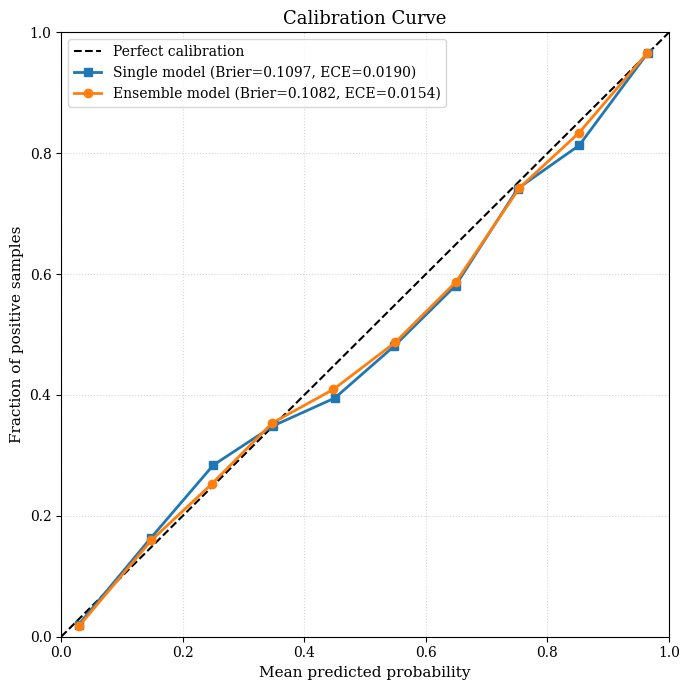


Calibration plot saved successfully.

Final configuration saved successfully.
Seed 42 model is ready for subsequent XAI analysis.

CLASSIFICATION PIPELINE COMPLETED SUCCESSFULLY
Number of independent models: 25
Total number of features: 776
Classification threshold: 0.50

Generated output files:
- Individual XGBoost models
- final_recommended_config.joblib
- xgb_final_summary.csv
- xgb_test_model_comparison.csv
- ppv_npv_prevalence_sensitivity.csv
- xgb_calibration_metrics.csv
- calibration_xgb_final.png


In [ ]:

# ============================================================
# XGBoost Classification
# 25 Independent Runs + Ensemble Evaluation
#
# Includes:
# 1. Image- and mask-based feature extraction
# 2. Training of 25 independent XGBoost models
# 3. Model evaluation at a fixed threshold of 0.5
# 4. Ensemble evaluation
# 5. PPV/NPV analysis at different prevalence levels
# 6. Sensitivity at 95% specificity
# 7. Calibration analysis
# 8. Saving trained models for subsequent SHAP/XAI analysis
# ============================================================

import os
import cv2
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    brier_score_loss
)
from sklearn.calibration import calibration_curve
from IPython.display import display

warnings.filterwarnings("ignore")


# ============================================================
# 1. CONFIGURATION
# ============================================================

ALIGNED_CSV = r"Classification\Final_Feature_MergedPosNeg_2.5D_DecAtt_S41_ALIGNED_FULL_FIXED.csv"


MODEL_SAVE_DIR = r"Classification\saved_xgb_models_FINAL_v3"


N_REPEATS = 25

IMG_POS_DIR = (
    r"DatasetResized320png\resized_images320"
)

IMG_NEG_DIR = (
    r"DatasetNegative2\resized_images_NegOnly_Full_320"
)

MASK_POS_DIR = (
    r"Classification\pred_masks_2.5D_DecAtt_P320"
)

MASK_NEG_DIR = (
    r"C:\LIDC_IDRI_Project\Classification"
    r"\pred_masks_2.5D_DecAtt_P320_NEGATIVE"
)

IMG_SIZE = 320
CLASSIFICATION_THRESHOLD = 0.5

os.makedirs(MODEL_SAVE_DIR, exist_ok=True)


# ============================================================
# 2. LOAD FEATURE DATASET
# ============================================================

df_feat = pd.read_csv(ALIGNED_CSV)

required_columns = ["image_name", "label", "split"]

missing_columns = [
    col for col in required_columns
    if col not in df_feat.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


def norm_name(x):
    """Return the image filename without its extension."""
    return os.path.splitext(os.path.basename(str(x).strip()))[0]


df = df_feat.copy()

df["_name_clean"] = df["image_name"].apply(norm_name)

# Assign image paths according to class labels.
df["image_path"] = df.apply(
    lambda row: os.path.join(
        IMG_POS_DIR if row["label"] == 1 else IMG_NEG_DIR,
        f"{row['_name_clean']}.png"
    ),
    axis=1
)

# Assign predicted mask paths according to class labels.
df["pred_mask_path"] = df.apply(
    lambda row: os.path.join(
        MASK_POS_DIR if row["label"] == 1 else MASK_NEG_DIR,
        f"{row['_name_clean']}.png"
    ),
    axis=1
)

df.drop(columns=["_name_clean"], inplace=True)

# Verify image and predicted mask availability.
missing_images = (~df["image_path"].apply(os.path.exists)).sum()
missing_masks = (~df["pred_mask_path"].apply(os.path.exists)).sum()

if missing_images > 0:
    raise FileNotFoundError(
        f"{missing_images} image files were not found."
    )

if missing_masks > 0:
    raise FileNotFoundError(
        f"{missing_masks} predicted mask files were not found."
    )

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nClass distribution:")
display(
    df["label"].value_counts().sort_index().rename(
        index={0: "Negative", 1: "Positive"}
    ).to_frame("Number of samples")
)


# ============================================================
# 3. IMAGE AND MASK FEATURE EXTRACTION
# ============================================================

def load_img(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if img is None:
        raise FileNotFoundError(
            "An image could not be loaded."
        )

    return (
        cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        .astype(np.float32) / 255.0
    )


def load_mask(path):
    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        raise FileNotFoundError(
            "A predicted mask could not be loaded."
        )

    return (
        cv2.resize(mask, (IMG_SIZE, IMG_SIZE))
        .astype(np.float32) / 255.0
    )


def extract_img_mask_features(row):

    img = load_img(row["image_path"])
    mask = load_mask(row["pred_mask_path"])

    features = [
        img.mean(),
        img.std(),
        img.max(),
        mask.mean(),
        mask.sum(),
        (mask > 0.5).mean()
    ]

    masked_img = img * (mask > 0.5)

    features += [
        masked_img.mean(),
        masked_img.std()
    ]

    return np.array(features, dtype=np.float32)


print("\nExtracting image and mask features...")

img_feats = np.vstack(
    df.apply(extract_img_mask_features, axis=1)
)

# Extract the 768 deep feature columns.
feature_cols = [
    col for col in df.columns
    if col.startswith("f_")
]

if len(feature_cols) != 768:
    raise ValueError(
        f"Expected 768 deep features, but found {len(feature_cols)}."
    )

img_feat_cols = [
    "img_mean",
    "img_std",
    "img_max",
    "mask_mean",
    "mask_area",
    "mask_ratio",
    "masked_mean",
    "masked_std"
]

all_feature_cols = feature_cols + img_feat_cols

# Combine deep and handcrafted features.
X_all = np.hstack([
    df[feature_cols].values,
    img_feats
])

y_all = df["label"].values.astype(int)
split_all = df["split"].values

if X_all.shape[1] != 776:
    raise ValueError(
        f"Expected 776 total features, but found {X_all.shape[1]}."
    )

print("\nFeature extraction completed.")
print("Deep features:", len(feature_cols))
print("Image and mask features:", len(img_feat_cols))
print("Total features:", X_all.shape[1])


# ============================================================
# 4. PATIENT-LEVEL DATA SPLITS AND STANDARDIZATION
# ============================================================

tr_mask = split_all == "train"
va_mask = split_all == "val"
te_mask = split_all == "test"

X_train_raw = X_all[tr_mask]
y_train = y_all[tr_mask]

X_val_raw = X_all[va_mask]
y_val = y_all[va_mask]

X_test_raw = X_all[te_mask]
y_test = y_all[te_mask]

if any(
    len(x) == 0
    for x in [X_train_raw, X_val_raw, X_test_raw]
):
    raise ValueError(
        "One or more dataset splits are empty."
    )

# Fit the scaler using training data only.
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

print("\nDataset split sizes:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

scale_pos_weight = (
    np.sum(y_train == 0) /
    np.sum(y_train == 1)
)

print(f"\nScale positive weight: {scale_pos_weight:.4f}")


# ============================================================
# 5. EVALUATION METRICS
# Fixed classification threshold: 0.5
# ============================================================

def evaluate(
    y_true,
    y_prob,
    threshold=CLASSIFICATION_THRESHOLD
):

    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Specificity": tn / (tn + fp + 1e-8),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        )
    }


# ============================================================
# 6. XGBOOST CONFIGURATION
# ============================================================

xgb_params = dict(
    n_estimators=1000,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.5,
    min_child_weight=3,
    eval_metric="logloss",
    early_stopping_rounds=30,
    n_jobs=-1
)


# ============================================================
# 7. TRAIN 25 INDEPENDENT XGBOOST MODELS
# ============================================================

records = []
test_probs_all = []
best_iters = []

print(f"\nTraining {N_REPEATS} independent XGBoost models...")

for repeat in range(N_REPEATS):

    seed = 42 + repeat

    clf = XGBClassifier(
        **xgb_params,
        random_state=seed
    )

    clf.fit(
        X_train,
        y_train,
        eval_set=[
            (X_train, y_train),
            (X_val, y_val)
        ],
        verbose=False
    )

    best_iters.append(clf.best_iteration)

    # Store test probabilities for ensemble evaluation.
    test_prob = clf.predict_proba(X_test)[:, 1]
    test_probs_all.append(test_prob)

    # Evaluate each individual model on all three splits.
    for split_name, (XX, yy) in zip(
        ["Train", "Val", "Test"],
        [
            (X_train, y_train),
            (X_val, y_val),
            (X_test, y_test)
        ]
    ):

        probabilities = clf.predict_proba(XX)[:, 1]

        metrics = evaluate(yy, probabilities)

        metrics.update({
            "Split": split_name,
            "Repeat": repeat + 1
        })

        records.append(metrics)

    # Save each trained model and its associated scaler.
    model_path = os.path.join(
        MODEL_SAVE_DIR,
        f"xgb_seed{seed}.joblib"
    )

    joblib.dump(
        {
            "model": clf,
            "scaler": scaler,
            "feature_cols": all_feature_cols,
            "seed": seed
        },
        model_path
    )

    if (repeat + 1) % 5 == 0 or repeat == 0:

        print(
            f"Completed {repeat + 1}/{N_REPEATS} runs | "
            f"Seed: {seed} | "
            f"Best iteration: {clf.best_iteration}"
        )

print("\nTraining completed.")
print(f"All {N_REPEATS} models were saved successfully.")


# ============================================================
# 8. INDIVIDUAL MODEL PERFORMANCE
# Mean ± Standard Deviation Across 25 Runs
# ============================================================

df_metrics = pd.DataFrame(records)

summary = []

for split in ["Train", "Val", "Test"]:

    split_df = (
        df_metrics[df_metrics["Split"] == split]
        .drop(columns=["Split", "Repeat"])
    )

    row = {"Split": split}

    for col in split_df.columns:

        row[col] = (
            f"{split_df[col].mean():.4f} "
            f"± {split_df[col].std():.4f}"
        )

    summary.append(row)


df_summary = pd.DataFrame(summary)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

print("\n" + "=" * 90)
print("INDIVIDUAL MODEL PERFORMANCE (25 RUNS)")
print("=" * 90)

display(df_summary)

df_summary.to_csv(
    "xgb_final_summary.csv",
    index=False
)


# ============================================================
# 9. ENSEMBLE EVALUATION
# Mean Probability Across 25 Models
# ============================================================

test_probs_all = np.asarray(test_probs_all)

ensemble_test_prob = np.mean(
    test_probs_all,
    axis=0
)

# Seed 42 is used as the representative single model.
single_model_test_prob = test_probs_all[0]

single_metrics = evaluate(
    y_test,
    single_model_test_prob
)

ensemble_metrics = evaluate(
    y_test,
    ensemble_test_prob
)

comparison_rows = []

for model_name, metrics in [
    ("Single model", single_metrics),
    ("Ensemble model", ensemble_metrics)
]:

    row = {"Model": model_name}

    row.update({
        key: f"{value:.4f}"
        for key, value in metrics.items()
    })

    comparison_rows.append(row)


df_comparison = pd.DataFrame(comparison_rows)

print("\n" + "=" * 90)
print("TEST PERFORMANCE COMPARISON")
print("=" * 90)

display(df_comparison)

df_comparison.to_csv(
    "xgb_test_model_comparison.csv",
    index=False
)


# ============================================================
# 10. PPV AND NPV AT DIFFERENT PREVALENCE LEVELS
# Based on Ensemble Predictions at Threshold 0.5
# ============================================================

print("\n" + "=" * 90)
print("PPV AND NPV AT DIFFERENT PREVALENCE LEVELS")
print("=" * 90)

sensitivity = ensemble_metrics["Recall"]
specificity = ensemble_metrics["Specificity"]


def ppv_npv_at_prevalence(sens, spec, prevalence):

    ppv = (
        sens * prevalence
    ) / (
        sens * prevalence +
        (1 - spec) * (1 - prevalence) + 1e-12
    )

    npv = (
        spec * (1 - prevalence)
    ) / (
        spec * (1 - prevalence) +
        (1 - sens) * prevalence + 1e-12
    )

    return ppv, npv


current_prevalence = y_test.mean()

scenarios = {
    f"Current test prevalence ({current_prevalence * 100:.1f}%)":
        current_prevalence,

    "Hypothetical prevalence (5%)": 0.05,
    "Hypothetical prevalence (10%)": 0.10,
    "Hypothetical prevalence (20%)": 0.20
}

prevalence_rows = []

for scenario, prevalence in scenarios.items():

    ppv, npv = ppv_npv_at_prevalence(
        sensitivity,
        specificity,
        prevalence
    )

    prevalence_rows.append({
        "Scenario": scenario,
        "Prevalence": f"{prevalence * 100:.1f}%",
        "PPV": f"{ppv:.4f}",
        "NPV": f"{npv:.4f}"
    })


df_prevalence = pd.DataFrame(prevalence_rows)

display(df_prevalence)

df_prevalence.to_csv(
    "ppv_npv_prevalence_sensitivity.csv",
    index=False
)


# ============================================================
# 11. SENSITIVITY AT 95% SPECIFICITY
# ============================================================

print("\n" + "=" * 90)
print("SENSITIVITY AT 95% SPECIFICITY")
print("=" * 90)

fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    ensemble_test_prob
)

valid_indices = np.where(fpr <= 0.05)[0]

if len(valid_indices) > 0:

    # Select the highest sensitivity while maintaining
    # a specificity of at least 95%.
    best_index = valid_indices[
        np.argmax(tpr[valid_indices])
    ]

    sens_at_95spec = tpr[best_index]
    actual_specificity = 1 - fpr[best_index]
    threshold_at_95spec = roc_thresholds[best_index]

    print(f"Threshold: {threshold_at_95spec:.4f}")
    print(f"Sensitivity: {sens_at_95spec:.4f}")
    print(f"Specificity: {actual_specificity:.4f}")

else:

    sens_at_95spec = 0.0
    actual_specificity = np.nan
    threshold_at_95spec = np.nan

    print("No threshold achieved at least 95% specificity.")


# ============================================================
# 12. CALIBRATION ANALYSIS
# Single Model vs. Ensemble Model
# ============================================================

print("\n" + "=" * 90)
print("CALIBRATION ANALYSIS")
print("=" * 90)


def expected_calibration_error(
    y_true,
    y_prob,
    n_bins=10
):

    bin_edges = np.linspace(0, 1, n_bins + 1)

    n = len(y_true)
    ece = 0.0

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i < n_bins - 1:
            mask = (
                (y_prob >= lower) &
                (y_prob < upper)
            )
        else:
            mask = (
                (y_prob >= lower) &
                (y_prob <= upper)
            )

        if mask.sum() == 0:
            continue

        bin_accuracy = y_true[mask].mean()
        bin_confidence = y_prob[mask].mean()

        ece += (
            mask.sum() / n
        ) * abs(bin_accuracy - bin_confidence)

    return ece


# Brier scores.
brier_single = brier_score_loss(
    y_test,
    single_model_test_prob
)

brier_ensemble = brier_score_loss(
    y_test,
    ensemble_test_prob
)

# Expected calibration errors.
ece_single = expected_calibration_error(
    y_test,
    single_model_test_prob,
    n_bins=10
)

ece_ensemble = expected_calibration_error(
    y_test,
    ensemble_test_prob,
    n_bins=10
)

df_calibration = pd.DataFrame([
    {
        "Model": "Single model",
        "Brier score": brier_single,
        "ECE": ece_single
    },
    {
        "Model": "Ensemble model",
        "Brier score": brier_ensemble,
        "ECE": ece_ensemble
    }
])

display(df_calibration.round(4))

df_calibration.to_csv(
    "xgb_calibration_metrics.csv",
    index=False
)


# ============================================================
# 13. CALIBRATION PLOT
# ============================================================

prob_true_single, prob_pred_single = calibration_curve(
    y_test,
    single_model_test_prob,
    n_bins=10,
    strategy="uniform"
)

prob_true_ensemble, prob_pred_ensemble = calibration_curve(
    y_test,
    ensemble_test_prob,
    n_bins=10,
    strategy="uniform"
)

fig, ax = plt.subplots(figsize=(7, 7))

# Perfect calibration reference line.
ax.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Perfect calibration"
)

# Single model.
ax.plot(
    prob_pred_single,
    prob_true_single,
    marker="s",
    linewidth=2,
    markersize=6,
    label=(
        f"Single model "
        f"(Brier={brier_single:.4f}, ECE={ece_single:.4f})"
    )
)

# Ensemble model.
ax.plot(
    prob_pred_ensemble,
    prob_true_ensemble,
    marker="o",
    linewidth=2,
    markersize=6,
    label=(
        f"Ensemble model "
        f"(Brier={brier_ensemble:.4f}, ECE={ece_ensemble:.4f})"
    )
)

ax.set_xlabel(
    "Mean predicted probability",
    fontsize=11
)

ax.set_ylabel(
    "Fraction of positive samples",
    fontsize=11
)

ax.set_title(
    "Calibration Curve",
    fontsize=13
)

ax.legend(
    loc="upper left",
    fontsize=10
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.grid(
    True,
    linestyle=":",
    alpha=0.5
)

plt.tight_layout()

plt.savefig(
    "calibration_xgb_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nCalibration plot saved successfully.")


# ============================================================
# 14. SAVE FINAL CONFIGURATION FOR XAI
# ============================================================

FINAL_CONFIG_PATH = os.path.join(
    MODEL_SAVE_DIR,
    "final_recommended_config.joblib"
)

# The representative single model is the Seed 42 model.
seed42_model_path = os.path.join(
    MODEL_SAVE_DIR,
    "xgb_seed42.joblib"
)

if not os.path.exists(seed42_model_path):
    raise FileNotFoundError(
        "The Seed 42 model file was not found."
    )

seed42_model = joblib.load(seed42_model_path)["model"]

final_config = {
    "model": seed42_model,
    "scaler": scaler,
    "feature_cols": all_feature_cols,
    "classification_threshold": CLASSIFICATION_THRESHOLD,
    "sensitivity_at_95_specificity": float(sens_at_95spec),
    "threshold_at_95_specificity": float(threshold_at_95spec),
    "brier_score": float(brier_ensemble),
    "ece": float(ece_ensemble),
    "test_metrics_single_model": single_metrics,
    "test_metrics_ensemble": ensemble_metrics
}

joblib.dump(
    final_config,
    FINAL_CONFIG_PATH
)

print("\nFinal configuration saved successfully.")
print("Seed 42 model is ready for subsequent XAI analysis.")


# ============================================================
# 15. FINAL OUTPUT SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CLASSIFICATION PIPELINE COMPLETED SUCCESSFULLY")
print("=" * 70)

print(f"Number of independent models: {N_REPEATS}")
print(f"Total number of features: {X_all.shape[1]}")
print(f"Classification threshold: {CLASSIFICATION_THRESHOLD:.2f}")

print("\nGenerated output files:")
print("- Individual XGBoost models")
print("- final_recommended_config.joblib")
print("- xgb_final_summary.csv")
print("- xgb_test_model_comparison.csv")
print("- ppv_npv_prevalence_sensitivity.csv")
print("- xgb_calibration_metrics.csv")
print("- calibration_xgb_final.png")


-------------------------------------------

### ROC and Precision–Recall Curve Analysis

This cell evaluates and compares the classification performance of the proposed 2.5D DecAtt model and the 2D baseline using ROC and Precision–Recall (PR) curves.

Deep features (`f_*`) are loaded directly from the corresponding CSV files, while the eight handcrafted image and mask features are extracted dynamically from the original images and predicted masks. Ensemble predictions are generated by averaging the predicted probabilities of all saved XGBoost models.

The resulting two-panel figure presents the ROC and PR curves for both approaches and provides a visual comparison of their classification performance. These results are presented in **Figure 13** and complement Table 10.


Processing 2.5D_DecAtt...
   Loaded dataset: (84727, 774)
   Extracting handcrafted image and mask features (this may take several minutes)...
   Test set: 12,116 samples, 776 features
   Completed: 2.5D_DecAtt

Processing 2D_Baseline...
   Loaded dataset: (84727, 774)
   Extracting handcrafted image and mask features (this may take several minutes)...
   Test set: 12,116 samples, 776 features
   Completed: 2D_Baseline


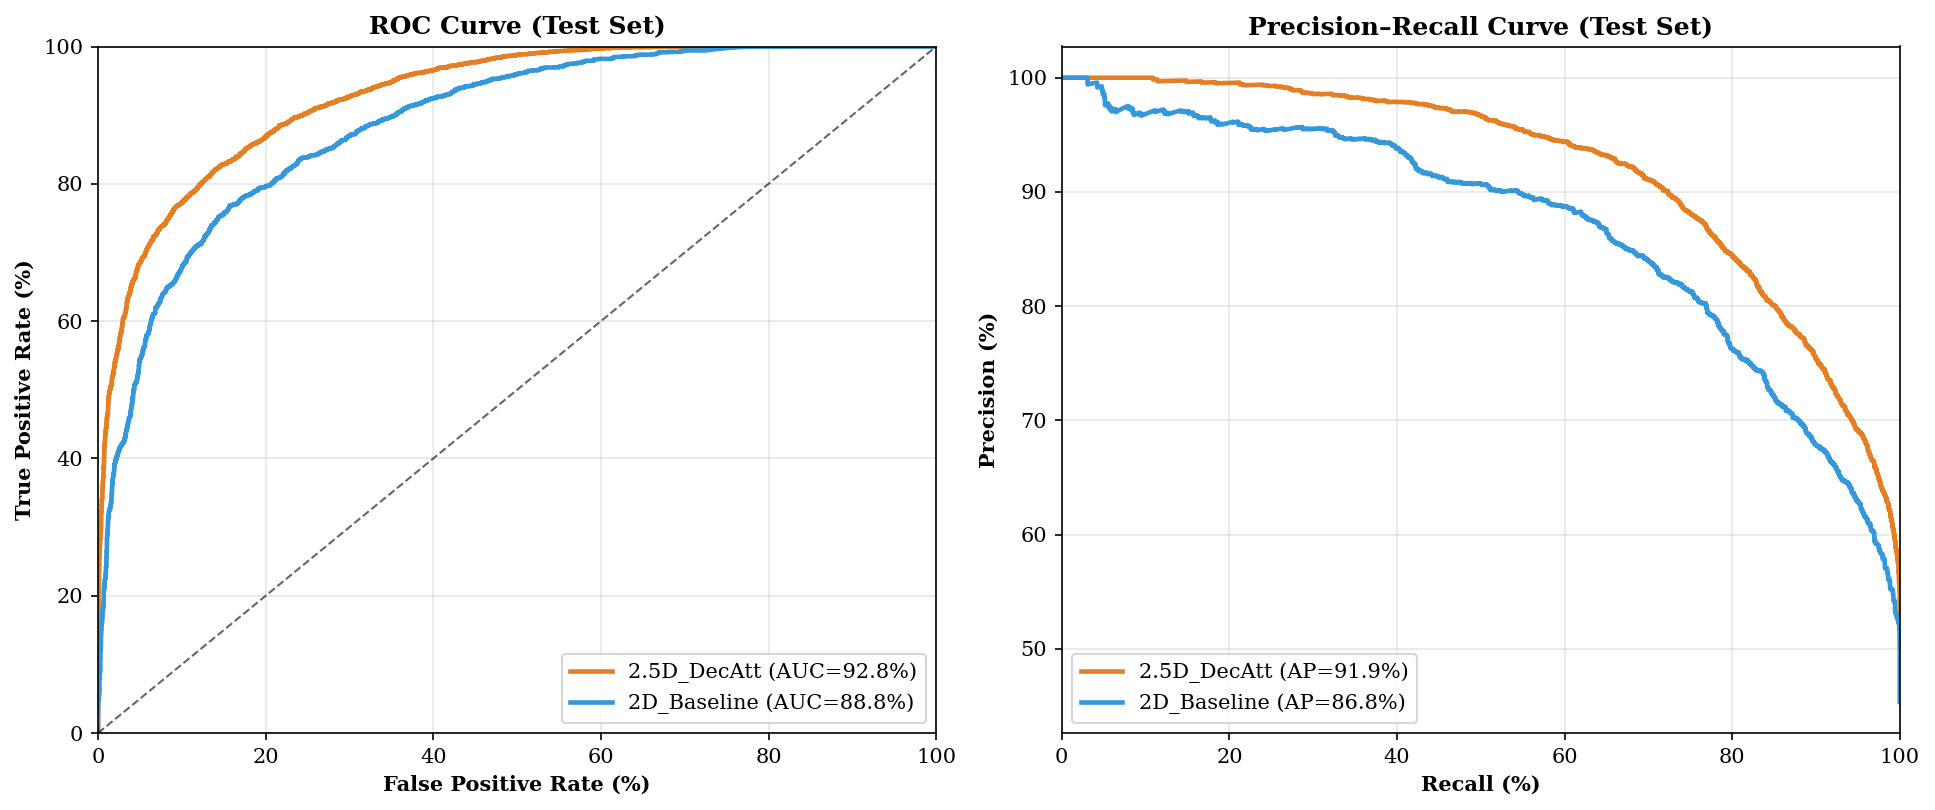


Figure saved successfully: Classification_ROC_PR_DecAtt_vs_Baseline.png


In [ ]:

# ============================================================
# ROC AND PRECISION-RECALL CURVES
# Comparison of 2.5D_DecAtt and 2D_Baseline
#
# A two-panel figure complementing Table 10.
#
# Important:
# - Deep features (f_*) are loaded directly from the CSV files.
# - The eight handcrafted image and mask features are extracted
#   dynamically from the corresponding images and predicted masks.
# - The handcrafted features are not read from the CSV files.
# - Ensemble predictions are obtained by averaging probabilities
#   from all saved XGBoost models.
#
# Cell: Cell_ROC_PR
# ============================================================

import os
import cv2
import glob
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)


# ============================================================
# Configuration
# ============================================================

IMG_SIZE = 320

CONFIGS = {
    "2.5D_DecAtt": {
        "csv": r"Classification\Final_Feature_MergedPosNeg_2.5D_DecAtt_S41_ALIGNED_FULL_FIXED.csv",
        "model_dir": r"Classification\saved_xgb_models_FINAL_v3",
        "img_pos_dir": r"data\DatasetResized320png\resized_images320",
        "img_neg_dir": r"data\DatasetNegative2\resized_images_NegOnly_Full_320",
        "mask_pos_dir": r"Classification\pred_masks_2.5D_DecAtt",
        "mask_neg_dir": r"Classification\pred_masks_2.5D_DecAtt_NEGATIVE",
        "color": "#E67E22",
    },

    "2D_Baseline": {
        "csv": r"Classification\Final_Feature_MergedPosNeg_Baseline_2D_S41_ALIGNED_FULL_FIXED.csv",
        "model_dir": r"Classification\saved_xgb_models_Baseline_FINAL",
        "img_pos_dir": r"DatasetResized320png\resized_images320",
        "img_neg_dir": r"DatasetNegative2\resized_images_NegOnly_Full_320",
        "mask_pos_dir": r"Classification\pred_masks_Baseline_2D",
        "mask_neg_dir": r"Classification\pred_masks_Baseline_2D_Negative",
        "color": "#3498DB",
    },
}


# ============================================================
# Image and Mask Utilities
# ============================================================

def norm_name(x):
    """Remove the .png extension and surrounding whitespace."""

    return str(x).replace(".png", "").strip()


def load_img(path):
    """Load and normalize a grayscale image."""

    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if img is None:
        return np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.float32)

    return (
        cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        .astype(np.float32) / 255.0
    )


def load_mask(path):
    """Load and normalize a predicted segmentation mask."""

    mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        return np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.float32)

    return (
        cv2.resize(mask, (IMG_SIZE, IMG_SIZE))
        .astype(np.float32) / 255.0
    )


def extract_img_mask_features(row):
    """
    Extract eight handcrafted features from an image
    and its corresponding predicted segmentation mask.
    """

    img = load_img(row["image_path"])
    mask = load_mask(row["pred_mask_path"])

    features = [
        img.mean(),
        img.std(),
        img.max(),
        mask.mean(),
        mask.sum(),
        (mask > 0.5).mean()
    ]

    masked_img = img * (mask > 0.5)

    features.extend([
        masked_img.mean(),
        masked_img.std()
    ])

    return np.array(features, dtype=np.float32)


# ============================================================
# Feature Loading and Test Set Preparation
# ============================================================

def load_full_pipeline(cfg):
    """
    Load deep features from the CSV, extract eight handcrafted
    image and mask features, and prepare the scaled test set.

    The StandardScaler is fitted exclusively on the training set.
    """

    df = pd.read_csv(cfg["csv"])

    # Normalize image names
    df["_name_clean"] = df["image_name"].apply(norm_name)

    # Assign image paths according to the class label
    df["image_path"] = df.apply(
        lambda row: os.path.join(
            cfg["img_pos_dir"] if row["label"] == 1
            else cfg["img_neg_dir"],
            f"{row['_name_clean']}.png"
        ),
        axis=1
    )

    # Assign predicted mask paths according to the class label
    df["pred_mask_path"] = df.apply(
        lambda row: os.path.join(
            cfg["mask_pos_dir"] if row["label"] == 1
            else cfg["mask_neg_dir"],
            f"{row['_name_clean']}.png"
        ),
        axis=1
    )

    df.drop(columns=["_name_clean"], inplace=True)

    print(f"   Loaded dataset: {df.shape}")

    print(
        "   Extracting handcrafted image and mask features "
        "(this may take several minutes)..."
    )

    # Extract eight handcrafted features
    img_feats = np.vstack(
        df.apply(extract_img_mask_features, axis=1)
    )

    # Load the 768 deep features
    feature_cols = [
        col for col in df.columns
        if col.startswith("f_")
    ]

    deep_features = df[feature_cols].values

    # Combine deep and handcrafted features
    X_all = np.hstack([
        deep_features,
        img_feats
    ])

    y_all = df["label"].values

    split_all = (
        df["split"]
        .astype(str)
        .str.strip()
        .str.lower()
        .values
    )

    # Identify training and test samples
    train_mask = split_all == "train"
    test_mask = split_all == "test"

    X_train_raw = X_all[train_mask]
    X_test_raw = X_all[test_mask]

    y_test = y_all[test_mask]

    # Fit the scaler using training data only
    scaler = StandardScaler()
    scaler.fit(X_train_raw)

    # Transform the held-out test set
    X_test = scaler.transform(X_test_raw)

    print(
        f"   Test set: {X_test.shape[0]:,} samples, "
        f"{X_test.shape[1]} features"
    )

    return X_test, y_test


# ============================================================
# Ensemble Probability Prediction
# ============================================================

def get_ensemble_probs(model_dir, X_test):
    """
    Load all saved XGBoost models and calculate ensemble
    probabilities by averaging their individual predictions.
    """

    model_paths = sorted(
        glob.glob(
            os.path.join(model_dir, "xgb_seed*.joblib")
        )
    )

    assert len(model_paths) > 0, (
        f"No saved XGBoost models were found in: {model_dir}"
    )

    all_probs = []

    for path in model_paths:

        bundle = joblib.load(path)

        probs = bundle["model"].predict_proba(X_test)[:, 1]

        all_probs.append(probs)

    ensemble_probs = np.mean(all_probs, axis=0)

    return ensemble_probs


# ============================================================
# MAIN EXECUTION
# ============================================================

results = {}

for name, cfg in CONFIGS.items():

    print(f"\nProcessing {name}...")

    X_test, y_test = load_full_pipeline(cfg)

    probs = get_ensemble_probs(
        cfg["model_dir"],
        X_test
    )

    results[name] = {
        "y_true": y_test,
        "probs": probs,
        "color": cfg["color"]
    }

    print(f"   Completed: {name}")


# ============================================================
# TWO-PANEL ROC AND PRECISION-RECALL FIGURE
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    dpi=150
)


# ------------------------------------------------------------
# Panel A: ROC Curves
# ------------------------------------------------------------

ax1 = axes[0]

for name, res in results.items():

    fpr, tpr, _ = roc_curve(
        res["y_true"],
        res["probs"]
    )

    roc_auc = auc(fpr, tpr)

    ax1.plot(
        fpr * 100,
        tpr * 100,
        color=res["color"],
        linewidth=2.2,
        label=f"{name} (AUC={roc_auc * 100:.1f}%)"
    )

# Random classifier reference line
ax1.plot(
    [0, 100],
    [0, 100],
    "k--",
    linewidth=1,
    alpha=0.6
)

ax1.set_xlabel(
    "False Positive Rate (%)",
    fontweight="bold"
)

ax1.set_ylabel(
    "True Positive Rate (%)",
    fontweight="bold"
)

ax1.set_title(
    "ROC Curve (Test Set)",
    fontweight="bold"
)

ax1.set_xlim(0, 100)
ax1.set_ylim(0, 100)

ax1.legend(
    loc="lower right",
    fontsize=10
)

ax1.grid(alpha=0.3)


# ------------------------------------------------------------
# Panel B: Precision-Recall Curves
# ------------------------------------------------------------

ax2 = axes[1]

for name, res in results.items():

    precision, recall, _ = precision_recall_curve(
        res["y_true"],
        res["probs"]
    )

    ap = average_precision_score(
        res["y_true"],
        res["probs"]
    )

    ax2.plot(
        recall * 100,
        precision * 100,
        color=res["color"],
        linewidth=2.2,
        label=f"{name} (AP={ap * 100:.1f}%)"
    )

ax2.set_xlabel(
    "Recall (%)",
    fontweight="bold"
)

ax2.set_ylabel(
    "Precision (%)",
    fontweight="bold"
)

ax2.set_title(
    "Precision–Recall Curve (Test Set)",
    fontweight="bold"
)

ax2.set_xlim(0, 100)

ax2.legend(
    loc="lower left",
    fontsize=10
)

ax2.grid(alpha=0.3)


# ============================================================
# Figure Layout and Saving
# ============================================================

plt.tight_layout()

plt.savefig(
    "Classification_ROC_PR_DecAtt_vs_Baseline.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\nFigure saved successfully: "
    "Classification_ROC_PR_DecAtt_vs_Baseline.png"
)
